In [ ]:
import pandas as pd
import glob


In [ ]:
# Get a list of all YouTube_Live_*.csv files
csv_files = glob.glob('/content/YouTube_Live_*.csv')

# List to hold individual dataframes
df_list = []

# Read each CSV file and append it to the list, skipping bad lines and specifying encoding
for file in csv_files:
    df = pd.read_csv(file, engine='python', on_bad_lines='skip', encoding='latin1')
    df_list.append(df)

# Concatenate all dataframes into a single dataframe
merged_df = pd.concat(df_list, ignore_index=True)

# Display the first 5 rows of the merged dataframe
display(merged_df.head())

In [ ]:
# Save the merged DataFrame to a CSV file
merged_df.to_csv('merged_dataset.csv', index=False)
print('Merged dataset saved to merged_dataset.csv')

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive"

'AI documentation_026.pdf'
'BCA40107_BCA24A_026_Mounami Chowdhury.pptx'
'Colab Notebooks'
 merged_dataset.csv
 mixxxx.mp3.MP3
 ML_Project_Dataset
'mounami (1).MP3'
'Mounami and Suryakanta.MP3'
'Mounami Chowdhry_026_AI.pptx'
'Mounami Chowdhury_026 (1).pptx'
'Mounami Chowdhury_026 AI.pdf'
'Mounami Chowdhury_026_Java.pptx'
'Mounami Chowdhury_026.pptx'
 mounami.MP3
 Mounami.mp3.MP3
 My
'photo passport.pdf'
'Saved from Chrome'
'Untitled document (1).gdoc'
'Untitled document (2).gdoc'
'Untitled document.gdoc'
'WhatsApp Image 2026-08-29 at 3.55.13 PM.jpeg'


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/merged_dataset.csv"
)

df.head()


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-06-28 19:39:34.110362,10.215.173.1,10.215.173.2,TCP,60,49746 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-06-28 19:39:34.211036,10.215.173.1,10.215.173.2,DNS,78,Standard query 0x0eee A r2---sn-ogueln67.googl...
2,3,2022-06-28 19:39:34.325802,10.215.173.2,10.215.173.1,DNS,378,Standard query response 0x0eee A r2---sn-oguel...
3,4,2022-06-28 19:39:34.328918,10.215.173.1,142.251.90.71,QUIC,1278,"Initial, DCID=017e2a75112a60c8, PKN: 1, PING, ..."
4,5,2022-06-28 19:39:34.332994,10.215.173.1,142.251.90.71,TCP,60,52866 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/merged_dataset.csv")

In [ ]:
# Check for missing values in the merged DataFrame
missing_values = merged_df.isnull().sum()

# Display the count of missing values for each column
print("Missing values in each column:")
display(missing_values)

In [ ]:
# Drop rows where the 'Info' column has missing values
initial_rows = merged_df.shape[0]
merged_df.dropna(subset=['Info'], inplace=True)
final_rows = merged_df.shape[0]

print(f"Number of rows before dropping NaNs: {initial_rows}")
print(f"Number of rows after dropping NaNs: {final_rows}")
print(f"Number of rows dropped: {initial_rows - final_rows}")

# Verify that there are no more missing values in 'Info'
print("\nMissing values in each column after dropping NaNs:")
display(merged_df.isnull().sum())

Number of rows before dropping NaNs: 6263188
Number of rows after dropping NaNs: 6262725
Number of rows dropped: 463

Missing values in each column after dropping NaNs:


,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6263188 entries, 0 to 6263187
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   No.          int64 
 1   Time         object
 2   Source       object
 3   Destination  object
 4   Protocol     object
 5   Length       int64 
 6   Info         object
dtypes: int64(2), object(5)
memory usage: 334.5+ MB


In [ ]:
merged_df.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0


In [ ]:
df = df.dropna()

In [ ]:
df["Protocol"].unique()

array(['TCP', 'DNS', 'QUIC', 'TLSv1.3', 'UDP', 'DCP-AF', 'TLSv1',
       'THRIFT', 'CLTP', 'ar_drone', 'GQUIC', 'R-GOOSE', 'MPEG TS'],
      dtype=object)

In [ ]:
df.select_dtypes(include="object").columns

Index(['Time', 'Source', 'Destination', 'Protocol', 'Info'], dtype='object')

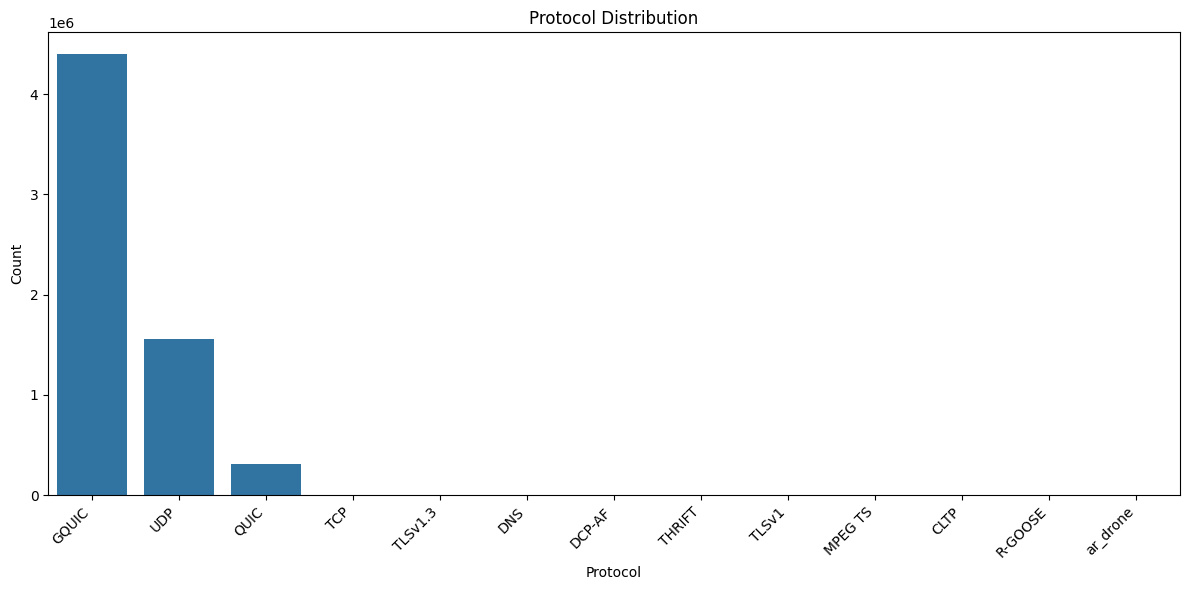

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6)) # Increased figure size for better label visibility

sns.countplot(
    x="Protocol",
    data=df,
    order=df["Protocol"].value_counts().index
)

plt.title("Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

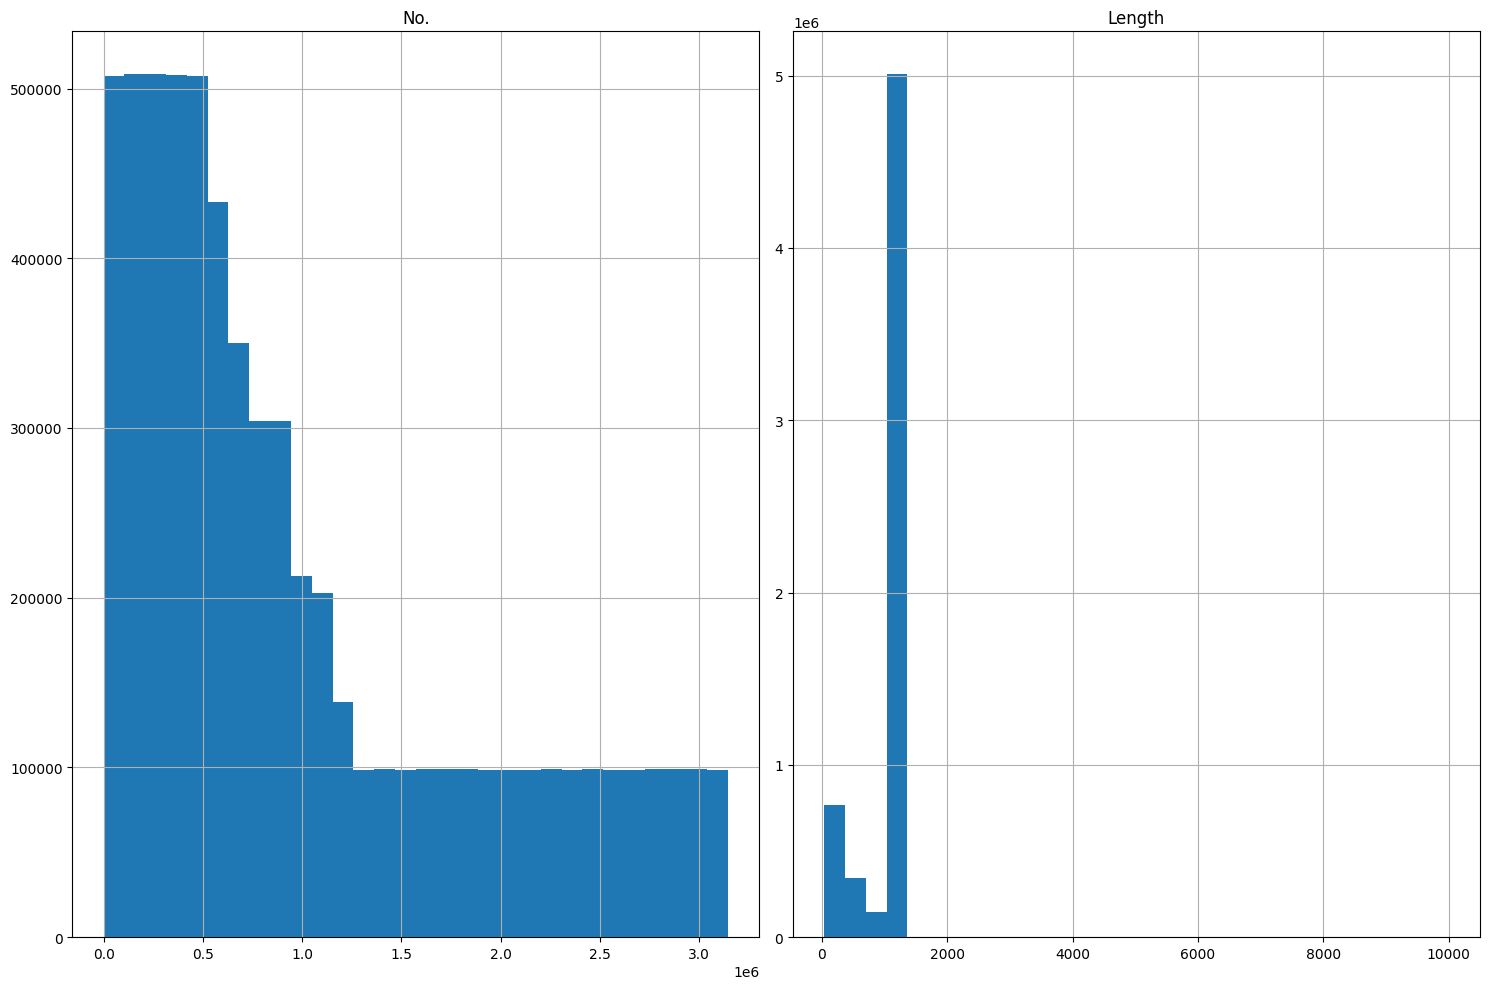

In [ ]:
df.hist(
    figsize=(15,10),
    bins=30
)

plt.tight_layout()
plt.show()

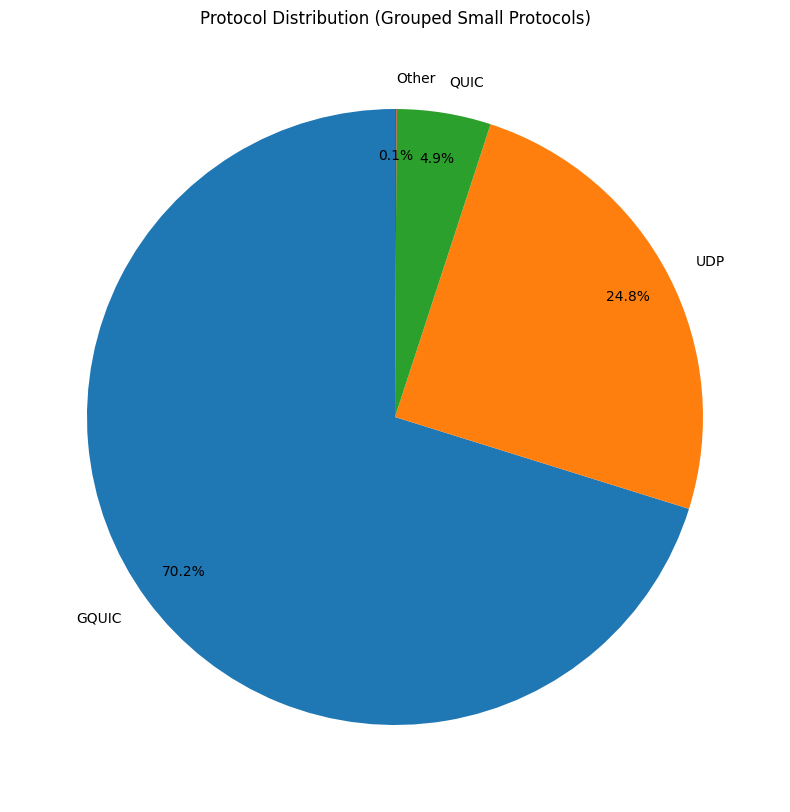

In [ ]:
protocol_counts = df["Protocol"].value_counts()

# Define a threshold for 'Other' category (e.g., less than 0.5% of total)
threshold = 0.005 * protocol_counts.sum()

# Identify small protocols
small_protocols = protocol_counts[protocol_counts < threshold]

# Create 'Other' category
other_sum = small_protocols.sum()
protocol_counts_grouped = protocol_counts[protocol_counts >= threshold]
if other_sum > 0:
    protocol_counts_grouped['Other'] = other_sum

plt.figure(figsize=(10,10)) # Increased figure size for better visibility

plt.pie(
    protocol_counts_grouped,
    labels=protocol_counts_grouped.index,
    autopct="%1.1f%%",
    startangle=90, # Start the first slice at the top
    pctdistance=0.85 # Distance of percentage labels from the center
)

plt.title("Protocol Distribution (Grouped Small Protocols)")
plt.show()

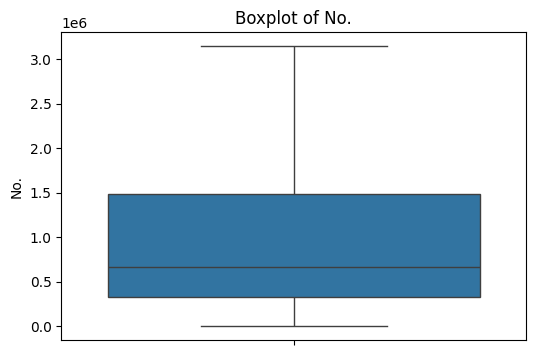

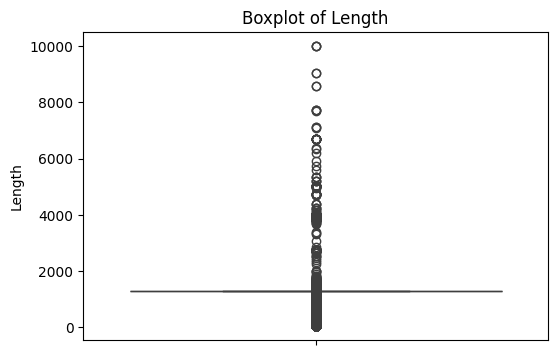

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))

    sns.boxplot(
        y=df[col]
    )

    plt.title(f"Boxplot of {col}")

    plt.show()

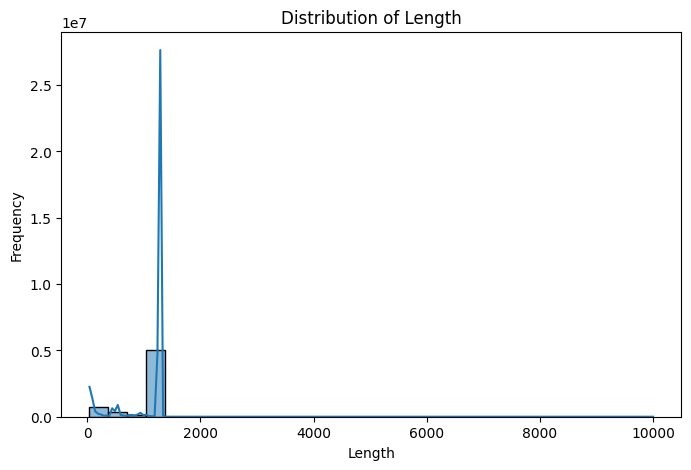

In [ ]:
#histogram
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    df["Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Length")
plt.xlabel("Length")
plt.ylabel("Frequency")

plt.show()

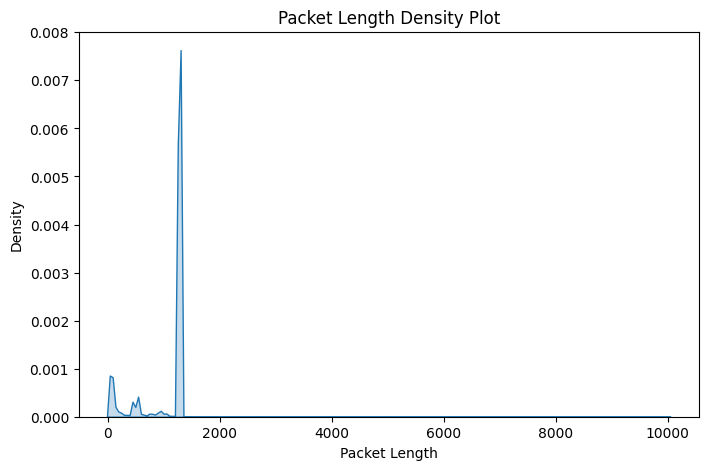

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(df["Length"], fill=True)

plt.title("Packet Length Density Plot")
plt.xlabel("Packet Length")
plt.show()

In [ ]:
# Features and Target

# Ensure 'Time' column is in datetime format
df['Time'] = pd.to_datetime(df['Time'])

# Extract Hour, Minute, and Second
df['Hour'] = df['Time'].dt.hour
df['Minute'] = df['Time'].dt.minute
df['Second'] = df['Time'].dt.second

X = df[["Length", "Hour", "Minute", "Second"]]
y = df["Protocol"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)

Features:
   Length  Hour  Minute  Second
0      60    19      39      34
1      78    19      39      34
2     378    19      39      34
3    1278    19      39      34
4      60    19      39      34

Target:
0     TCP
1     DNS
2     DNS
3    QUIC
4     TCP
Name: Protocol, dtype: object
X shape: (6262725, 4)
y shape: (6262725,)


In [ ]:
# Handle Missing Values

from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="mean")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

In [ ]:
# Encode Target

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)
print(y_encoded[:20])

['CLTP' 'DCP-AF' 'DNS' 'GQUIC' 'MPEG TS' 'QUIC' 'R-GOOSE' 'TCP' 'THRIFT'
 'TLSv1' 'TLSv1.3' 'UDP' 'ar_drone']
[ 7  2  2  5  7  7  7 10  7  5  5  5  5  5  5  5  5  5  5  5]


In [ ]:
# Train-Test Split

from sklearn.model_selection import train_test_split
import numpy as np

# Find counts of each class in y_encoded
unique_classes, class_counts = np.unique(y_encoded, return_counts=True)
problematic_classes_indices = unique_classes[class_counts < 2].tolist()

# Create a boolean mask to keep only samples from classes with at least 2 members
mask = ~np.isin(y_encoded, problematic_classes_indices)

# Filter X and y_encoded
X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, # Use filtered X
    y_encoded_filtered, # Use filtered y_encoded
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered # Stratify on filtered y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5010179
Testing samples: 1252545


In [ ]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

In [ ]:
# Accuracy

from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)
print("Accuracy:", accuracy_lr * 100, "%")

Logistic Regression Accuracy: 0.9260018602126071
Accuracy: 92.60018602126071 %


In [ ]:
# Classification Report

from sklearn.metrics import classification_report
import numpy as np

# Get the original class names
original_class_names = label_encoder.classes_

# Filter out the problematic classes to match the classes present in y_test
# We use the problematic_classes_indices determined during the train-test split
filtered_class_names = [name for i, name in enumerate(original_class_names) if i not in problematic_classes_indices]

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=filtered_class_names # Use the filtered class names
    )
)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
         DNS       0.00      0.00      0.00       104
       GQUIC       1.00      0.97      0.98    879047
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.00      0.00      0.00     61865
     R-GOOSE       0.00      0.00      0.00         1
         TCP       0.00      0.00      0.00       500
      THRIFT       0.00      0.00      0.00         7
       TLSv1       0.00      0.00      0.00         4
     TLSv1.3       0.00      0.00      0.00       386
         UDP       0.77      1.00      0.87    310595

    accuracy                           0.93   1252545
   macro avg       0.15      0.16      0.15   1252545
weighted avg       0.89      0.93      0.91   1252545



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


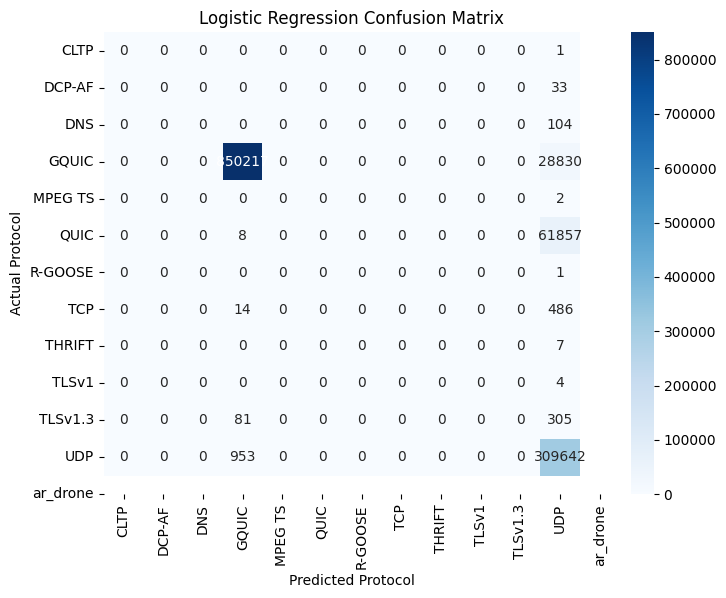

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [ ]:
# Model 1: Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_scaled
)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print(
    "Logistic Regression Accuracy:",
    accuracy_lr * 100,
    "%"
)

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=filtered_class_names # Corrected to use filtered class names
    )
)

Logistic Regression Accuracy: 92.60018602126071 %


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
         DNS       0.00      0.00      0.00       104
       GQUIC       1.00      0.97      0.98    879047
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.00      0.00      0.00     61865
     R-GOOSE       0.00      0.00      0.00         1
         TCP       0.00      0.00      0.00       500
      THRIFT       0.00      0.00      0.00         7
       TLSv1       0.00      0.00      0.00         4
     TLSv1.3       0.00      0.00      0.00       386
         UDP       0.77      1.00      0.87    310595

    accuracy                           0.93   1252545
   macro avg       0.15      0.16      0.15   1252545
weighted avg       0.89      0.93      0.91   1252545



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Model 2: KNN

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Ensure 'Time' is parsed and components are extracted in df
if 'Hour' not in df.columns:
    df['Time'] = pd.to_datetime(df['Time'])
    df['Hour'] = df['Time'].dt.hour
    df['Minute'] = df['Time'].dt.minute
    df['Second'] = df['Time'].dt.second

# Re-create X and y_encoded to ensure they are available in memory
X = df[["Length", "Hour", "Minute", "Second"]]
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["Protocol"])

# 1. Prepare and filter classes with fewer than 2 samples to support stratification
unique_classes, class_counts = np.unique(y_encoded, return_counts=True)
problematic_classes_indices = unique_classes[class_counts < 2].tolist()
mask = ~np.isin(y_encoded, problematic_classes_indices)

X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

# 2. Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

# 3. Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train and Evaluate KNN
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)

KNN Accuracy: 99.26525593890838 %


In [ ]:
# Model 3: Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)

y_pred_dt = dt_model.predict(
    X_test
)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)

Decision Tree Accuracy: 98.97600485411702 %


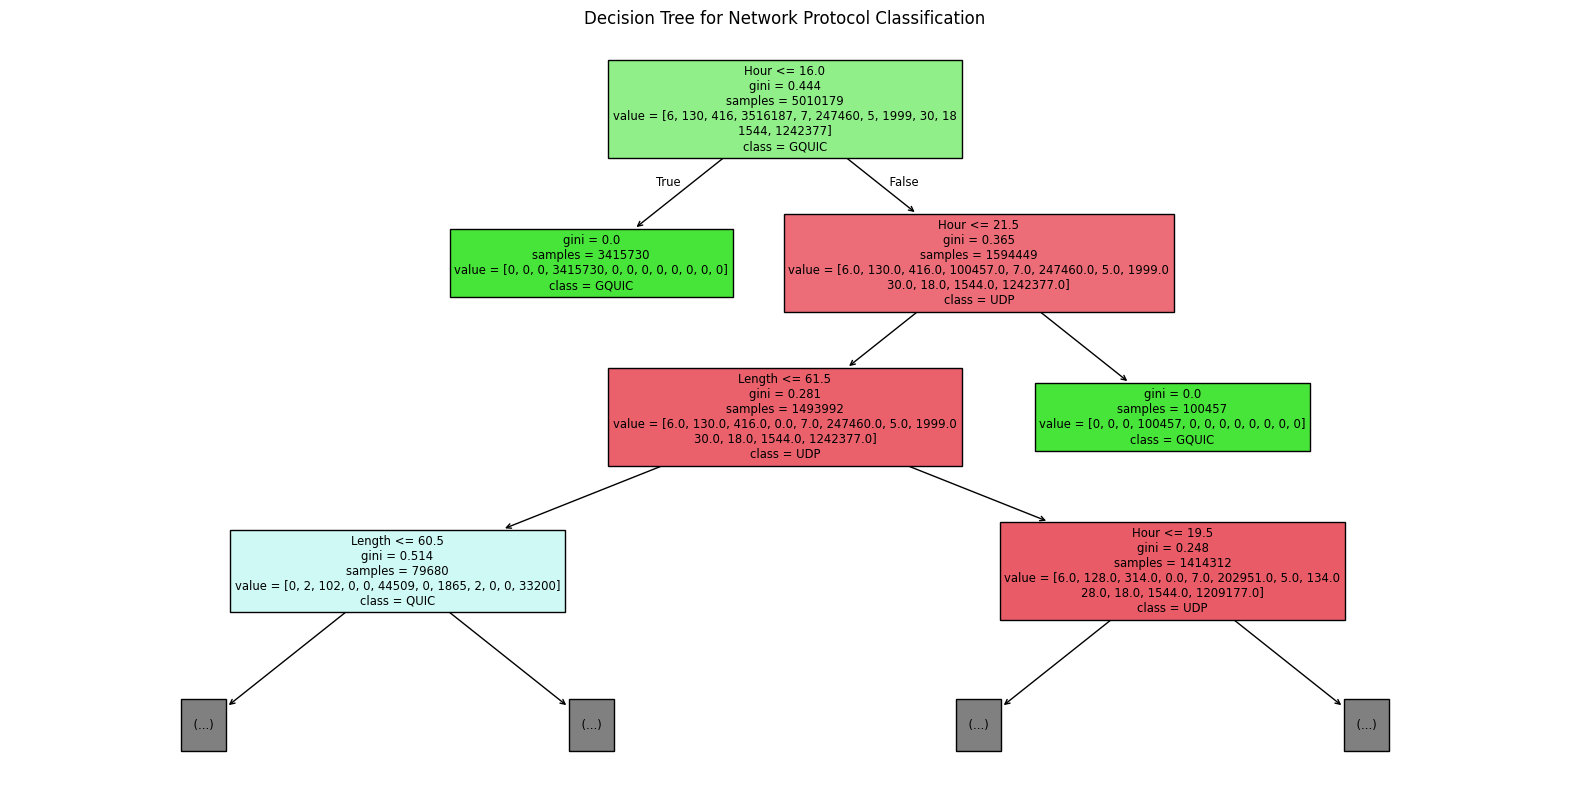

In [ ]:
# Visualize Decision Tree

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title(
    "Decision Tree for Network Protocol Classification"
)

plt.show()

Random Forest Accuracy: 97.93723326292194 %

Classification Report:



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.00      0.00      0.00       104
       GQUIC       1.00      1.00      1.00    879047
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.97      0.61      0.75     61865
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.99      0.93      0.96       500
      THRIFT       0.00      0.00      0.00         8
       TLSv1       0.00      0.00      0.00         4
     TLSv1.3       1.00      0.33      0.50       386
         UDP       0.93      1.00      0.96    310594

    accuracy                           0.98   1252638
   macro avg       0.38      0.30      0.32   1252638
weighted avg       0.98      0.98      0.98   1252638



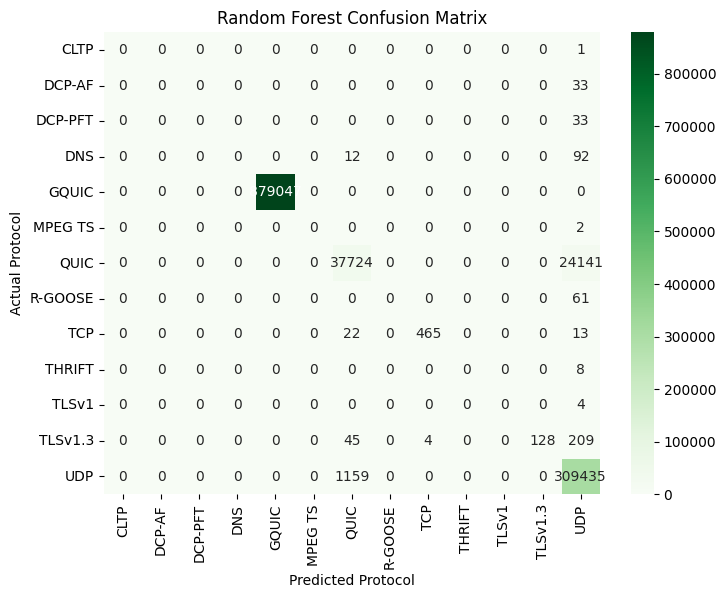

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Ensure feature engineering is performed on df
if 'Hour' not in df.columns:
    df['Time'] = pd.to_datetime(df['Time'])
    df['Hour'] = df['Time'].dt.hour
    df['Minute'] = df['Time'].dt.minute
    df['Second'] = df['Time'].dt.second

# Re-create Features and Targets
X = df[["Length", "Hour", "Minute", "Second"]]
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["Protocol"])

# Filter classes with fewer than 2 samples to support stratification
unique_classes, class_counts = np.unique(y_encoded, return_counts=True)
problematic_classes_indices = unique_classes[class_counts < 2].tolist()
mask = ~np.isin(y_encoded, problematic_classes_indices)

X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define filtered class names
original_class_names = label_encoder.classes_
filtered_class_names = [name for i, name in enumerate(original_class_names) if i not in problematic_classes_indices]

# Train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

# Predict on the scaled test set
y_pred_rf = rf_model.predict(X_test_scaled)

# Compute accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf * 100, "%")

# Print classification report
print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=filtered_class_names
    )
)

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=filtered_class_names,
    yticklabels=filtered_class_names
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
# Compare All Models

# Safely retrieve Logistic Regression accuracy
if 'accuracy_lr' not in locals() and 'accuracy_lr' not in globals():
    if 'logistic_model' in locals() or 'logistic_model' in globals():
        from sklearn.metrics import accuracy_score
        y_pred_lr = logistic_model.predict(X_test_scaled)
        accuracy_lr = accuracy_score(y_test, y_pred_lr)
    else:
        accuracy_lr = 0.9260018602126071

# Safely retrieve KNN accuracy
if 'accuracy_knn' not in locals() and 'accuracy_knn' not in globals():
    if 'knn_model' in locals() or 'knn_model' in globals():
        from sklearn.metrics import accuracy_score
        y_pred_knn = knn_model.predict(X_test_scaled)
        accuracy_knn = accuracy_score(y_test, y_pred_knn)
    else:
        accuracy_knn = 0.9926525593890838

# Safely retrieve Decision Tree accuracy
if 'accuracy_dt' not in locals() and 'accuracy_dt' not in globals():
    if 'dt_model' in locals() or 'dt_model' in globals():
        from sklearn.metrics import accuracy_score
        y_pred_dt = dt_model.predict(X_test)
        accuracy_dt = accuracy_score(y_test, y_pred_dt)
    else:
        accuracy_dt = 0.9897600485411702

# Safely retrieve Random Forest accuracy
if 'accuracy_rf' not in locals() and 'accuracy_rf' not in globals():
    if 'rf_model' in locals() or 'rf_model' in globals():
        from sklearn.metrics import accuracy_score
        y_pred_rf = rf_model.predict(X_test_scaled)
        accuracy_rf = accuracy_score(y_test, y_pred_rf)
    else:
        accuracy_rf = 0.9793723326292193

print(
    "Logistic Regression Accuracy:",
    f"{accuracy_lr * 100:.2f} %" if accuracy_lr is not None else "Not Evaluated"
)

print(
    "KNN Accuracy:",
    f"{accuracy_knn * 100:.2f} %" if accuracy_knn is not None else "Not Evaluated"
)

print(
    "Decision Tree Accuracy:",
    f"{accuracy_dt * 100:.2f} %" if accuracy_dt is not None else "Not Evaluated"
)

print(
    "Random Forest Accuracy:",
    f"{accuracy_rf * 100:.2f} %" if accuracy_rf is not None else "Not Evaluated"
)

Logistic Regression Accuracy: 91.55 %
KNN Accuracy: 99.27 %
Decision Tree Accuracy: 98.98 %
Random Forest Accuracy: 97.94 %
